In [23]:
import pandas as pd
import os

# Dataset directory
path = "../data/raw/"

# Load important datasets
files = {
    "orders": "olist_orders_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "categories": "product_category_name_translation.csv"
}

data = {}

for name, filename in files.items():
    data[name] = pd.read_csv(path + filename)

# Dataset overview
for name, df in data.items():
    print("\nDataset:", name)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())
    print("-" * 50)



Dataset: orders
Shape: (99441, 8)
Columns: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
Missing values: 4908
Duplicate rows: 0
--------------------------------------------------

Dataset: customers
Shape: (99441, 5)
Columns: ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']
Missing values: 0
Duplicate rows: 0
--------------------------------------------------

Dataset: items
Shape: (112650, 7)
Columns: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']
Missing values: 0
Duplicate rows: 0
--------------------------------------------------

Dataset: payments
Shape: (103886, 5)
Columns: ['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']
Missing values: 0
Duplicate rows: 0
----------------------------

In [24]:

orders = data["orders"]

# Count missing values in each column
missing = orders.isnull().sum()

# Calculate missing percentage
missing_percentage = (
    orders.isnull().mean() * 100
).round(2)

# Create summary table
missing_report = pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage": missing_percentage
})

# Display columns having missing values
print(missing_report[missing_report["Missing Values"] > 0])


                               Missing Values  Missing Percentage
order_approved_at                         160                0.16
order_delivered_carrier_date             1783                1.79
order_delivered_customer_date            2965                2.98


In [25]:

print(orders["order_status"].value_counts())

print("\nOrder Status Percentage:")
print(
    orders["order_status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Order Status Percentage:
order_status
delivered      97.02
shipped         1.11
canceled        0.63
unavailable     0.61
invoiced        0.32
processing      0.30
created         0.01
approved        0.00
Name: proportion, dtype: float64


In [26]:

print(orders.info())

print("\nFirst 5 records:")
display(orders.head())


<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB
None

First 5 records:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [27]:

# Create missing-value indicators
orders["missing_approved"] = orders["order_approved_at"].isnull()

orders["missing_carrier"] = orders[
    "order_delivered_carrier_date"
].isnull()

orders["missing_delivery"] = orders[
    "order_delivered_customer_date"
].isnull()

# Analyze missing dates by order status
missing_by_status = orders.groupby("order_status").agg(
    total_orders=("order_id", "count"),
    missing_approval=("missing_approved", "sum"),
    missing_carrier=("missing_carrier", "sum"),
    missing_delivery=("missing_delivery", "sum")
)

display(missing_by_status)


,total_orders,missing_approval,missing_carrier,missing_delivery
order_status,,,,
approved,2,0,2,2
canceled,625,141,550,619
created,5,5,5,5
delivered,96478,14,2,8
invoiced,314,0,314,314
processing,301,0,301,301
shipped,1107,0,0,1107
unavailable,609,0,609,609


In [28]:

# Create a working copy
orders_clean = data["orders"].copy()

# Identify date columns
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

# Convert columns into datetime
for col in date_columns:
    orders_clean[col] = pd.to_datetime(
        orders_clean[col],
        errors="coerce"
    )

# Check updated datatypes
print(orders_clean.dtypes)

# Check missing values after conversion
print("\nMissing values:")
print(orders_clean[date_columns].isnull().sum())


order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
missing_approved                           bool
missing_carrier                            bool
missing_delivery                           bool
dtype: object

Missing values:
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [29]:

print("Total rows:", len(orders_clean))

print(
    "Unique order IDs:",
    orders_clean["order_id"].nunique()
)

print(
    "Duplicate order IDs:",
    orders_clean["order_id"].duplicated().sum()
)


Total rows: 99441
Unique order IDs: 99441
Duplicate order IDs: 0


In [30]:

# Create a copy for validation
df = orders_clean.copy()

# Check whether approval happened before purchase
invalid_approval = df[
    df["order_approved_at"] <
    df["order_purchase_timestamp"]
]

# Check whether carrier date happened before approval
invalid_carrier = df[
    df["order_delivered_carrier_date"] <
    df["order_approved_at"]
]

# Check whether delivery happened before carrier handover
invalid_delivery = df[
    df["order_delivered_customer_date"] <
    df["order_delivered_carrier_date"]
]

print("Approval before purchase:",
      len(invalid_approval))

print("Carrier before approval:",
      len(invalid_carrier))

print("Delivery before carrier:",
      len(invalid_delivery))


Approval before purchase: 0
Carrier before approval: 1359
Delivery before carrier: 23


In [31]:

# Find delivered orders with missing delivery dates
delivered_missing = df[
    (df["order_status"] == "delivered") &
    (
        df["order_delivered_customer_date"].isnull() |
        df["order_delivered_carrier_date"].isnull()
    )
]

print("Delivered orders with missing dates:",
      len(delivered_missing))

display(
    delivered_missing[
        [
            "order_id",
            "order_purchase_timestamp",
            "order_approved_at",
            "order_delivered_carrier_date",
            "order_delivered_customer_date"
        ]
    ].head(10)
)


Delivered orders with missing dates: 9


,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaT
20618,f5dd62b788049ad9fc0526e3ad11a097,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaT
43834,2ebdfc4f15f23b91474edf87475f108e,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaT
73222,2aa91108853cecb43c84a5dc5b277475,2017-09-29 08:52:58,2017-09-29 09:07:16,NaT,2017-11-20 19:44:47
79263,e69f75a717d64fc5ecdfae42b2e8e086,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaT
82868,0d3268bad9b086af767785e3f0fc0133,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaT
92643,2d858f451373b04fb5c984a1cc2defaf,2017-05-25 23:22:43,2017-05-25 23:30:16,NaT,NaT
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaT
98038,20edc82cf5400ce95e1afacc25798b31,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaT


In [32]:

# Calculate delivery duration
df["delivery_days"] = (
    df["order_delivered_customer_date"] -
    df["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Average delivery duration for delivered orders
delivered_orders = df[
    (df["order_status"] == "delivered") &
    (df["delivery_days"].notna())
]

print(
    "Average delivery time:",
    round(delivered_orders["delivery_days"].mean(), 2),
    "days"
)

print(
    "Median delivery time:",
    round(delivered_orders["delivery_days"].median(), 2),
    "days"
)


Average delivery time: 12.56 days
Median delivery time: 10.22 days


In [33]:

# Inspect carrier dates earlier than approval dates

display(
    invalid_carrier[
        [
            "order_id",
            "order_status",
            "order_purchase_timestamp",
            "order_approved_at",
            "order_delivered_carrier_date"
        ]
    ].head(15)
)


,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date
15,dcb36b511fcac050b97cd5c05de84dc3,delivered,2018-06-07 19:03:12,2018-06-12 23:31:02,2018-06-11 14:54:00
64,688052146432ef8253587b930b01a06d,delivered,2018-04-22 08:48:13,2018-04-24 18:25:22,2018-04-23 19:19:14
199,58d4c4747ee059eeeb865b349b41f53a,delivered,2018-07-21 12:49:32,2018-07-26 23:31:53,2018-07-24 12:57:00
210,412fccb2b44a99b36714bca3fef8ad7b,delivered,2018-07-22 22:30:05,2018-07-23 12:31:53,2018-07-23 12:24:00
415,56a4ac10a4a8f2ba7693523bb439eede,delivered,2018-07-22 13:04:47,2018-07-27 23:31:09,2018-07-24 14:03:00
481,32e4fa9bb468884309b58b9348de70c3,delivered,2018-07-04 16:49:21,2018-07-05 16:33:06,2018-07-05 14:50:00
483,4df92d82d79c3b52c7138679fa9b07fc,delivered,2018-07-24 11:32:11,2018-07-29 23:30:52,2018-07-26 14:46:00
585,16e38caa92e342c7780f68832f832d4d,delivered,2018-05-07 01:09:09,2018-05-07 16:52:39,2018-05-07 15:09:00
615,b9afddbdcfadc9a87b41a83271c3e888,delivered,2018-08-16 13:50:48,2018-08-16 14:05:13,2018-08-16 13:27:00
817,6051e6d3da9a50b7325cbe9c81025062,delivered,2018-07-03 23:40:16,2018-07-05 16:31:26,2018-07-04 12:14:00


In [34]:

print(
    invalid_carrier["order_status"]
    .value_counts()
)

print("\nStatus-wise percentage:")
print(
    invalid_carrier["order_status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


order_status
delivered    1350
shipped         9
Name: count, dtype: int64

Status-wise percentage:
order_status
delivered    99.34
shipped       0.66
Name: proportion, dtype: float64


In [35]:

# Calculate time difference in hours
invalid_carrier = invalid_carrier.copy()

invalid_carrier["hours_difference"] = (
    invalid_carrier["order_approved_at"] -
    invalid_carrier["order_delivered_carrier_date"]
).dt.total_seconds() / 3600

print(
    invalid_carrier["hours_difference"].describe()
)


count    1359.000000
mean       24.751987
std       115.307793
min         0.005833
25%         1.415417
50%        17.167778
75%        25.956667
max      4109.256111
Name: hours_difference, dtype: float64


In [36]:

display(
    invalid_delivery[
        [
            "order_id",
            "order_status",
            "order_approved_at",
            "order_delivered_carrier_date",
            "order_delivered_customer_date"
        ]
    ]
)


,order_id,order_status,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
6437,a1abeb653a4d4cd1e142ccb8c82cd069,delivered,2017-07-21 06:43:14,2017-07-28 16:57:58,2017-07-25 19:32:56
9553,383aa8b2724fe452d9ccd9934a8c628b,delivered,2017-07-02 21:10:20,2017-07-07 17:22:41,2017-07-06 14:27:51
13487,cb1134f9010d242e9515ad1c78ec0c39,delivered,2017-07-18 06:03:50,2017-07-20 19:22:02,2017-07-19 14:13:28
14474,dceb62e8fa94b46006c9554fed743df0,delivered,2017-07-22 11:45:11,2017-08-01 18:23:30,2017-07-26 18:09:10
19268,5f9d46795c3126674e52becb3a1a517f,delivered,2017-07-18 12:03:29,2017-07-20 23:03:42,2017-07-20 18:52:41
21338,8c78d01de3a9009e23d6877a7cc9be20,delivered,2016-10-08 18:13:44,2016-10-26 11:41:53,2016-10-25 17:51:46
22520,b27af682321527a6349f1761eb3f360c,delivered,2017-06-14 20:30:08,2017-06-27 14:51:54,2017-06-26 15:45:35
25393,1cc3ae63caffff2d6c3ee3e78e074acf,delivered,2017-08-08 21:45:15,2017-08-10 18:28:56,2017-08-10 18:05:38
25646,e37f11cae9985ca58f0b56f268720537,delivered,2017-07-27 10:10:16,2017-08-01 18:17:47,2017-07-31 17:49:56
27470,fa3e37584f4fdb1ded0e0de700dfcb4e,delivered,2017-07-30 19:45:09,2017-08-09 18:18:43,2017-08-01 21:13:01


In [37]:

# Distribution of delivery duration
print(
    delivered_orders["delivery_days"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)


count    96470.000000
mean        12.558217
std          9.546156
min          0.533414
25%          6.766204
50%         10.217477
75%         15.720182
90%         23.096377
95%         29.274046
99%         46.050262
max        209.628611
Name: delivery_days, dtype: float64


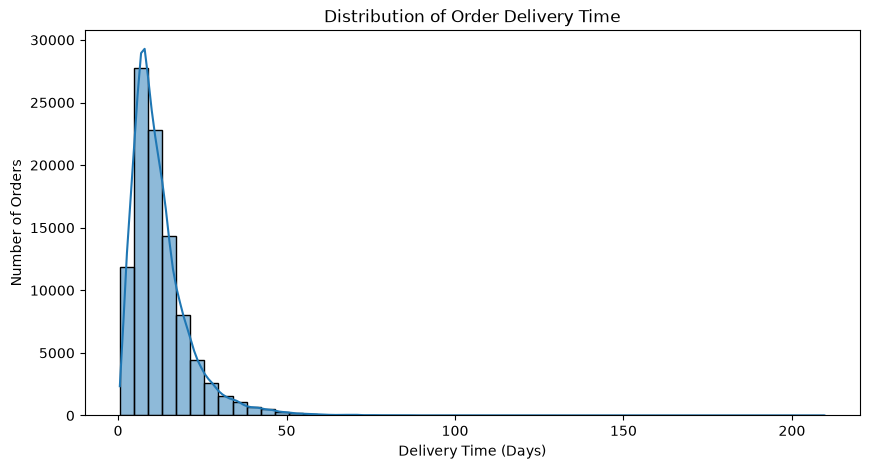

In [38]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    delivered_orders["delivery_days"],
    bins=50,
    kde=True
)

plt.title("Distribution of Order Delivery Time")
plt.xlabel("Delivery Time (Days)")
plt.ylabel("Number of Orders")

plt.show()


In [39]:
print(
    invalid_carrier["order_status"].value_counts()
)

order_status
delivered    1350
shipped         9
Name: count, dtype: int64


In [40]:
invalid_carrier = invalid_carrier.copy()

invalid_carrier["hours_difference"] = (
    invalid_carrier["order_approved_at"] -
    invalid_carrier["order_delivered_carrier_date"]
).dt.total_seconds() / 3600

display(
    invalid_carrier["hours_difference"].describe()
)

count    1359.000000
mean       24.751987
std       115.307793
min         0.005833
25%         1.415417
50%        17.167778
75%        25.956667
max      4109.256111
Name: hours_difference, dtype: float64

In [41]:
display(
    invalid_delivery[
        [
            "order_id",
            "order_status",
            "order_approved_at",
            "order_delivered_carrier_date",
            "order_delivered_customer_date"
        ]
    ]
)

,order_id,order_status,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
6437,a1abeb653a4d4cd1e142ccb8c82cd069,delivered,2017-07-21 06:43:14,2017-07-28 16:57:58,2017-07-25 19:32:56
9553,383aa8b2724fe452d9ccd9934a8c628b,delivered,2017-07-02 21:10:20,2017-07-07 17:22:41,2017-07-06 14:27:51
13487,cb1134f9010d242e9515ad1c78ec0c39,delivered,2017-07-18 06:03:50,2017-07-20 19:22:02,2017-07-19 14:13:28
14474,dceb62e8fa94b46006c9554fed743df0,delivered,2017-07-22 11:45:11,2017-08-01 18:23:30,2017-07-26 18:09:10
19268,5f9d46795c3126674e52becb3a1a517f,delivered,2017-07-18 12:03:29,2017-07-20 23:03:42,2017-07-20 18:52:41
21338,8c78d01de3a9009e23d6877a7cc9be20,delivered,2016-10-08 18:13:44,2016-10-26 11:41:53,2016-10-25 17:51:46
22520,b27af682321527a6349f1761eb3f360c,delivered,2017-06-14 20:30:08,2017-06-27 14:51:54,2017-06-26 15:45:35
25393,1cc3ae63caffff2d6c3ee3e78e074acf,delivered,2017-08-08 21:45:15,2017-08-10 18:28:56,2017-08-10 18:05:38
25646,e37f11cae9985ca58f0b56f268720537,delivered,2017-07-27 10:10:16,2017-08-01 18:17:47,2017-07-31 17:49:56
27470,fa3e37584f4fdb1ded0e0de700dfcb4e,delivered,2017-07-30 19:45:09,2017-08-09 18:18:43,2017-08-01 21:13:01


In [42]:
# Find negative delivery durations
negative_delivery = df[
    df["delivery_days"] < 0
]

print("Negative delivery durations:",
      len(negative_delivery))

display(
    negative_delivery[
        [
            "order_id",
            "order_purchase_timestamp",
            "order_delivered_customer_date",
            "delivery_days"
        ]
    ].head(10)
)

Negative delivery durations: 0


,order_id,order_purchase_timestamp,order_delivered_customer_date,delivery_days


In [43]:
# Sort invalid carrier records by the largest time gap
invalid_carrier = invalid_carrier.copy()

invalid_carrier["gap_hours"] = (
    invalid_carrier["order_approved_at"]
    - invalid_carrier["order_delivered_carrier_date"]
).dt.total_seconds() / 3600

# Inspect the 10 most extreme records
display(
    invalid_carrier.sort_values(
        "gap_hours", ascending=False
    )[
        [
            "order_id",
            "order_status",
            "order_approved_at",
            "order_delivered_carrier_date",
            "gap_hours"
        ]
    ].head(10)
)

,order_id,order_status,order_approved_at,order_delivered_carrier_date,gap_hours
25883,7c48bb55e8e4f7e56d412e9653db37bc,delivered,2018-07-16 18:50:22,2018-01-26 13:35:00,4109.256111
14562,1fab4ac9d85079b3da72a11475ae1685,delivered,2017-09-13 22:06:11,2017-09-04 13:10:23,224.930000
46163,0184d4ddb259e1a4cfc2871888cf97b8,delivered,2017-09-13 22:17:15,2017-09-04 14:05:50,224.190278
98710,1378f9601350615613cc8832d6789c5d,delivered,2017-09-13 22:03:51,2017-09-04 18:07:55,219.932222
41592,8554cb37f7158cb0b082a841d24a4589,delivered,2017-09-13 21:58:04,2017-09-04 19:12:19,218.762500
11738,cf72398d0690f841271b695bbfda82d2,delivered,2017-09-13 22:04:39,2017-09-04 20:12:41,217.866111
85393,40de47dfa620d667117e4a6067b6e1ec,delivered,2017-09-13 21:58:38,2017-09-04 20:36:58,217.361111
31211,bc4854efd86d9f42140c951c595d20c1,delivered,2017-09-13 22:00:51,2017-09-04 20:49:57,217.181667
55302,77ca435b03fbf991e5027e3776e37885,delivered,2017-09-13 21:56:08,2017-09-04 20:50:00,217.102222
68315,580f3268bc2075c5961b2d2929c7a35b,delivered,2017-09-13 22:03:42,2017-09-05 11:58:18,202.090000


In [44]:
reviews = data["reviews"]

review_missing = pd.DataFrame({
    "missing_count": reviews.isnull().sum(),
    "missing_percentage": (
        reviews.isnull().mean() * 100
    ).round(2)
})

display(
    review_missing.sort_values(
        "missing_percentage", ascending=False
    )
)

,missing_count,missing_percentage
review_comment_title,87656,88.34
review_comment_message,58247,58.70
review_id,0,0.00
review_score,0,0.00
order_id,0,0.00
review_creation_date,0,0.00
review_answer_timestamp,0,0.00
